<a href="https://colab.research.google.com/github/anaishinschberger-cloud/my_llm/blob/main/SimpleStories/02_transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1 : Imports

In [1]:
import torch
import torch.nn as nn
from torch.nn import functional as F

# Model architecture and training settings
batch_size = 64 # Number of sequences processed together in each batch
context_length = 256 # Maximum number of tokens available as context
max_iters = 8000
eval_interval = 500
learning_rate = 3e-4
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 100
n_embd = 384
n_head = 6
n_layer = 6
dropout = 0.2

torch.manual_seed(1337)

In [2]:
!pip -q install datasets
from datasets import load_dataset

dataset = load_dataset("SimpleStories/SimpleStories", split="train", streaming=True)

stories = list(dataset.shuffle(seed=42, buffer_size=10000).take(100000))

train_text = "\n\n".join(example["story"] for example in stories[:93000])
val_text = "\n\n".join(example["story"] for example in stories[93000:])

chars = sorted(set(train_text + val_text))

README.md:   0%|          | 0.00/4.18k [00:00<?, ?B/s]

3 : Prepare data

In [3]:
torch.manual_seed(1337)

vocab_size = len(chars)

# Convert between text characters and integer token IDs
char_to_id = {ch:i for i,ch in enumerate(chars)}
id_to_char = {i:ch for i,ch in enumerate(chars)}

encode = lambda s: [char_to_id[c] for c in s]
decode = lambda l: ''.join([id_to_char[i] for i in l])

train_data = torch.tensor(encode(train_text), dtype=torch.long)
val_data = torch.tensor(encode(val_text), dtype=torch.long)

# Sample context windows with targets shifted one token ahead
def get_batch(split):
    data = train_data if split == 'train' else val_data
    start_indices = torch.randint(len(data) - context_length, (batch_size,))
    inputs = torch.stack([data[i:i+context_length] for i in start_indices])
    targets = torch.stack([data[i+1:i+context_length+1] for i in start_indices])
    inputs, targets = inputs.to(device), targets.to(device)
    return inputs, targets

4 : validation

In [4]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

5 : class head

In [5]:
class Head(nn.Module):
    """ one head of self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(context_length, context_length)))

        self.dropout = nn.Dropout(dropout)

    def forward(self, inputs):
        # Input dimensions: batch size (B), sequence length (T), embedding dimension (C)
        # Each head returns one vector of length head_size per token
        B,T,C = inputs.shape
        k = self.key(inputs)
        q = self.query(inputs)
        # Scale query-key similarities by the inverse square root of the head dimension
        attention_weights = q @ k.transpose(-2,-1) * k.shape[-1]**-0.5 # Compute one attention score for each pair of sequence positions: (B, T, T)
        attention_weights = attention_weights.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # Mask future positions so each token can attend only to itself and earlier tokens
        attention_weights = F.softmax(attention_weights, dim=-1)
        attention_weights = self.dropout(attention_weights)
        # Combine value vectors using the attention weights after dropout
        v = self.value(inputs)
        out = attention_weights @ v
        return out

6 : class multi-head

In [6]:
class MultiHeadAttention(nn.Module):
    """ multiple heads of self-attention in parallel """

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(head_size * num_heads, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, inputs):
        out = torch.cat([h(inputs) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

7 : Define feedforward

In [7]:
class FeedFoward(nn.Module):
    """ a simple linear layer followed by a non-linearity """

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, inputs):
        return self.net(inputs)

8 : Create transformer block

In [8]:
class TransformerBlock(nn.Module):
    """ Transformer block: communication followed by computation """

    def __init__(self, n_embd, n_head):
        # Split the embedding dimension evenly across the attention heads
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedFoward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, inputs):
        inputs = inputs + self.sa(self.ln1(inputs))
        inputs = inputs + self.ffwd(self.ln2(inputs))
        return inputs

9 : GPT class

In [9]:
class GPTLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()
        # Learn separate embeddings for token identities and sequence positions
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(context_length, n_embd)
        self.blocks = nn.Sequential(*[TransformerBlock(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

        # Initialize linear and embedding weights with a small normal distribution and linear biases with zeros
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        # idx contains token IDs of shape (B, T); optional targets have the same shape
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # Position embeddings are shared across all sequences in the batch
        inputs = tok_emb + pos_emb
        inputs = self.blocks(inputs)
        inputs = self.ln_f(inputs)
        logits = self.lm_head(inputs) # Predict a vocabulary-sized vector of logits at every sequence position

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # Extend each sequence of token IDs by sampling one new token at a time
        for _ in range(max_new_tokens):
            # Keep only the latest context_length tokens for the next prediction
            idx_cond = idx[:, -context_length:]

            logits, loss = self(idx_cond)
            # Use the final position to predict the next token
            logits = logits[:, -1, :]

            probs = F.softmax(logits, dim=-1)
            # Sample from the predicted probabilities rather than always choosing the most likely token
            idx_next = torch.multinomial(probs, num_samples=1)

            idx = torch.cat((idx, idx_next), dim=1)
        return idx


10 : Create model and optimizer

In [10]:
model = GPTLanguageModel()
m = model.to(device)

print(sum(p.numel() for p in m.parameters())/1e6, 'M parameters')

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)


10.798926 M parameters


11 : Training

In [11]:
import time
start_time = time.monotonic()
max_seconds = 2 * 3600 + 40 * 60

import copy
best_loss = float('inf')

import matplotlib.pyplot as plt
steps = []
train_losses = []
val_losses = []

for iter in range(max_iters):

    # Monitor training and validation loss at regular intervals and on the final step
    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        steps.append(iter)
        train_losses.append(losses['train'].item())
        val_losses.append(losses['val'].item())
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")

        if losses['val'] < best_loss:
          best_loss = losses['val'].item()
          best_weights = copy.deepcopy(model.state_dict())

    input_batch, target_batch = get_batch('train')

    logits, loss = model(input_batch, target_batch)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if time.monotonic() - start_time >= max_seconds:
      print("Training time limit reached")
      break

model.load_state_dict(best_weights)

step 0: train loss 4.4810, val loss 4.4808
step 500: train loss 1.4155, val loss 1.4121
step 1000: train loss 1.0849, val loss 1.0840
step 1500: train loss 0.9798, val loss 0.9821
step 2000: train loss 0.9195, val loss 0.9250
step 2500: train loss 0.8864, val loss 0.8889
step 3000: train loss 0.8601, val loss 0.8616
step 3500: train loss 0.8406, val loss 0.8425
step 4000: train loss 0.8211, val loss 0.8228
step 4500: train loss 0.8064, val loss 0.8095
step 5000: train loss 0.7980, val loss 0.7973
step 5500: train loss 0.7832, val loss 0.7840
step 6000: train loss 0.7755, val loss 0.7791
step 6500: train loss 0.7654, val loss 0.7701
step 7000: train loss 0.7567, val loss 0.7627
step 7500: train loss 0.7493, val loss 0.7516
step 7999: train loss 0.7442, val loss 0.7510


<All keys matched successfully>

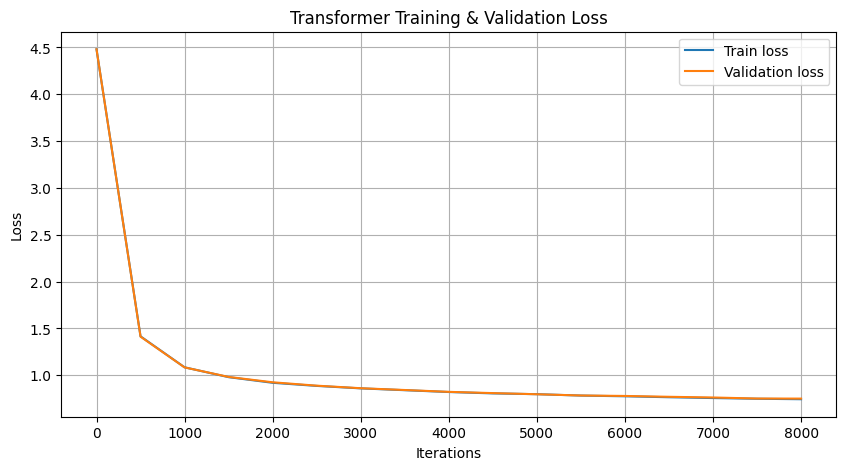

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(steps, train_losses, label='Train loss')
plt.plot(steps, val_losses, label='Validation loss')

plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.title('Transformer Training & Validation Loss')
plt.legend()
plt.grid(True)

plt.show()

12 : Trying it !

In [15]:
# Start generation with a single token whose ID is zero
model.eval()

initial_context = torch.zeros((1, 1), dtype=torch.long, device=device)

with torch.no_grad():
  print(decode(m.generate(initial_context, max_new_tokens=500)[0].tolist()))



As he held the star tightly, he noticed a small boy with big eyes. The other boy dreamed of stories and made a castle. He drew a small toy shell and quiet. What do you give up? My friends looked up, surprised but smiled and said, "These creatures ran alongside. The sky once heads above between two factories." The girl gasped. She closed her eyes and smiled. 

When she turned herself into a land where a girl named Kim gazed away at her paper. She wanted to learn to join her, but the superhero wa


13 : Trying it with a prompt

In [18]:
model.eval()

prompt = "Tom had a red ball. He gave it to Anna."

encoding = torch.tensor([encode(prompt)], dtype=torch.long, device=device)

with torch.no_grad():
  output = model.generate(encoding, max_new_tokens=400)
  print(decode(output[0].tolist()))

Tom had a red ball. He gave it to Anna. It ran and said, "We need to be neated, and they have a sigher." Samuel realized that friendship may trust each other, but not also a fish that make the best stories a lie.

Ice soft whisper swept through the trees. A girl with a bright smile where her sun was campirit. She had figures with a soft smile. She loved to collect clothes and pirates. One day, she discovered a map in a park that spoke 
